# Experimento 03 - Análise Temática de Diálogos

In [3]:
#pip install -r requirements.txt2

In [34]:
from langchain_openai import AzureChatOpenAI
from langchain_openai.embeddings import AzureOpenAIEmbeddings
from langchain_core.prompts import ChatPromptTemplate
from langchain_core.output_parsers import StrOutputParser
from dotenv import load_dotenv
import os
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.manifold import TSNE
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from tqdm import tqdm
from langchain_text_splitters import RecursiveCharacterTextSplitter
from langchain_community.document_loaders import PyPDFLoader
from sklearn.metrics.pairwise import cosine_similarity

In [5]:
load_dotenv()

llm = AzureChatOpenAI(
    model="gpt-4o", 
    openai_api_version=os.getenv("AZURE_OPENAI_API_VERSION"),  
    azure_endpoint=os.getenv("AZURE_OPENAI_ENDPOINT"),
    api_key=os.getenv("AZURE_OPENAI_API_KEY")
)

system_prompt = """
Você é um assistente inteligente que vai construir uma conversa entre duas personas. Considere que a conversa pode ser natural (pode ser como num formato de podcast). Seu trabalho e gerar uma conversa extensa que começa com tópicos relacionados à {topic_1}, mas que gradualmente se move para tópicos relacionados a {topic_2}.

Siga o seguinte padrão para a conversa:

Persona 1: [fala algo que pode ser relacionado a {topic_1}]
Persona 2: [responde, ainda relacionado a {topic_1} ou fazendo uma transição suave]
... 


---------------

Continue a conversa por pelo menos 100 trocas de mensagens
"""

prompt = ChatPromptTemplate.from_messages(
        [
            ("system", system_prompt),
            ("human", "Gere a conversa entre as duas personas."),
        ]
)

chain = prompt | llm | StrOutputParser()

In [6]:
response = chain.invoke({
    "topic_1": "história",
    "topic_2": "matemática"
})

In [7]:
def select_persona(message: str) -> str:
    if message.startswith("Persona 1:"):
        return "Persona 1"
    elif message.startswith("Persona 2:"):
        return "Persona 2"
    else:
        return "Unknown"

conversation_list = response.split("\n")
conversation_list = [line for line in conversation_list if line.strip() != ""]
conversation_list_persona = [{"persona": select_persona(line), "message": line[11:]} for line in conversation_list]

In [8]:
system_prompt_summary = """
Você é um assistente inteligente que vai resumir uma conversa entre duas personas. Você vai receber uma lista de mensagens, cada uma associada a uma persona (Persona 1 ou Persona 2). Seu trabalho é gerar um resumo conciso da conversa, dê enfase para o tópico principal discutido na conversa no momento atual (mesmo que o tópico tenha mudado ao longo da conversa). Os tópicos devem girar em torno de {topic_1} e {topic_2}.
"""

prompt_summary = ChatPromptTemplate.from_messages(
        [
            ("system", system_prompt_summary),
            ("human", "Resuma a conversa dada: {conversation}"),
        ]
)

chain_summary = prompt_summary | llm | StrOutputParser()

In [9]:
summary_list = []
buffer = []
for i in tqdm(range(len(conversation_list))):
    buffer.append(conversation_list[i])
    buffer_trimmed = buffer[-10:]  
    buffer_str = "\n".join(buffer_trimmed)
    response_summary = chain_summary.invoke({
        "topic_1": "história",
        "topic_2": "educação financeira",
        "conversation": buffer_str
    })
    summary_list.append(response_summary)

100%|██████████| 34/34 [01:09<00:00,  2.05s/it]


In [10]:
all_data_list = []
for i in range(len(conversation_list)):
    all_data_list.append({
        "summary": summary_list[i],
        "persona": conversation_list_persona[i]["persona"],
        "message": conversation_list_persona[i]["message"]
    })

os.makedirs("../data/conversation", exist_ok=True)

with open("../data/conversation/conversation_data.json", "w", encoding="utf-8") as f:
    json.dump(all_data_list, f, ensure_ascii=False, indent=4)

with open("../data/conversation/conversation_data.json", "r", encoding="utf-8") as f:
    loaded_content = json.load(f)   
    print(loaded_content[:5])

[{'summary': 'A conversa aborda como a Idade Média influenciou o mundo atual, destacando o impacto duradouro de eventos históricos em aspectos considerados fundamentais no presente.', 'persona': 'Persona 1', 'message': 'Você já parou para pensar o quanto a Idade Média influenciou o mundo de hoje? As vezes, fico impressionado como coisas que consideramos básicas tiveram origens tão distantes.'}, {'summary': 'A conversa aborda a influência da Idade Média no mundo atual, destacando como os feudos moldaram cidades modernas da Europa e o papel histórico dos castelos, que hoje são monumentos turísticos, mas com grande carga cultural e histórica.', 'persona': 'Persona 2', 'message': 'Verdade, é fascinante. Por exemplo, os feudos foram o alicerce para a formação de tantas cidades modernas da Europa. Ainda mais interessante é como os castelos, que foram essenciais na defesa, hoje são apenas monumentos turísticos, mas com uma carga histórica riquíssima.'}, {'summary': 'A conversa aborda o impact

In [ ]:
file_path_matematica = "pdfs2/MatematicaI.pdf"
file_path_historia   = "pdfs2/HistoriaI.pdf"

loader_historia   = PyPDFLoader(file_path_historia)
loader_matematica = PyPDFLoader(file_path_matematica)

pages_historia   = loader_historia.load()
pages_matematica = loader_matematica.load()

n_pages = 30
selected_historia   = pages_historia[:n_pages]
selected_matematica = pages_matematica[:n_pages]


In [22]:
embeddings = AzureOpenAIEmbeddings(
    model ="text-embedding-3-small",
    openai_api_version=os.getenv("AZURE_OPENAI_API_VERSION"),  
    azure_endpoint=os.getenv("AZURE_OPENAI_ENDPOINT"),
    api_key=os.getenv("AZURE_OPENAI_API_KEY")
)


In [27]:
text_splitter = RecursiveCharacterTextSplitter(
    chunk_size=5000,
    chunk_overlap=1500,
    length_function=len,
    is_separator_regex=False,
)

chunks_historia = text_splitter.split_documents(selected_historia)
chunks_matematica = text_splitter.split_documents(selected_matematica)
len(chunks_historia), len(chunks_matematica)

(58, 32)

In [28]:
chunks_conversation = []
for item in loaded_content:
    chunks_conversation.append(item['summary'])
len(chunks_conversation)

34

In [29]:
vectors_conversation = np.array(embeddings.embed_documents([chunk for chunk in chunks_conversation]))
vectors_historia = np.array(embeddings.embed_documents([chunk.page_content for chunk in chunks_historia]))
vectors_matematica = np.array(embeddings.embed_documents([chunk.page_content for chunk in chunks_matematica]))
all_vectors = np.concatenate([vectors_conversation, vectors_historia, vectors_matematica], axis=0)
vectors_conversation.shape, vectors_matematica.shape, vectors_historia.shape, all_vectors.shape

((34, 1536), (32, 1536), (58, 1536), (124, 1536))

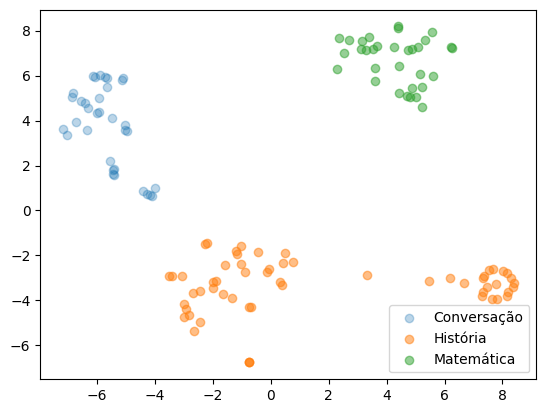

In [32]:
tsne = TSNE(n_components=2, random_state=42)
all_vectors_tsne = tsne.fit_transform(all_vectors)

plt.scatter(all_vectors_tsne[:len(vectors_conversation), 0], all_vectors_tsne[:len(vectors_conversation), 1], label="Conversação", alpha=0.3)

plt.scatter(all_vectors_tsne[len(vectors_conversation):len(vectors_historia) + len(vectors_conversation), 0], all_vectors_tsne[len(vectors_conversation):len(vectors_historia) + len(vectors_conversation), 1], label="História", alpha=0.5)
plt.scatter(all_vectors_tsne[len(vectors_historia) + len(vectors_conversation):, 0], all_vectors_tsne[len(vectors_historia) + len(vectors_conversation):, 1], label="Matemática", alpha=0.5)
plt.legend()
plt.show()

In [41]:
centroid_historia = np.mean(vectors_historia, axis=0)
centroid_matematica = np.mean(vectors_matematica, axis=0)

In [ ]:
similarity_to_historia = cosine_similarity(vectors_conversation, centroid_historia.reshape(1, -1))
similarity_to_matematica = cosine_similarity(vectors_conversation, centroid_matematica.reshape(1, -1))
content_and_similarities = []
for i in range(len(chunks_conversation)):
    content_and_similarities.append({
        "chunk": chunks_conversation[i],
        "similarity_to_historia": similarity_to_historia[i, 0],
        "similarity_to_matematica": similarity_to_matematica[i, 0]
    })
df = pd.DataFrame(content_and_similarities)
df.sort_values(by="similarity_to_matematica", ascending=False).head(10)

,chunk,similarity_to_historia,similarity_to_matematica
28,A conversa gira em torno da evolução e impacto...,0.377606,0.474493
30,A conversa gira em torno da história e impacto...,0.391729,0.460951
26,A conversa explora a evolução histórica e a un...,0.347954,0.458633
27,A conversa gira em torno da história e evoluçã...,0.371969,0.457965
33,A conversa gira em torno da conexão entre mate...,0.393151,0.455761
31,A conversa entre as personas abordou a relação...,0.418012,0.451342
18,A conversa aborda a evolução e o impacto da ma...,0.387341,0.449711
22,A conversa gira em torno da relação entre mate...,0.333734,0.449020
29,A conversa gira em torno da evolução e impacto...,0.350127,0.446200
14,A conversa gira em torno da disseminação e evo...,0.390208,0.444600


In [37]:
df.sort_values(by="similarity_to_historia", ascending=False).head(10)

,chunk,similarity_to_historia,similarity_to_matematica
4,A conversa foca na influência da Idade Média n...,0.530779,0.278315
8,A conversa entre Persona 1 e Persona 2 explora...,0.530170,0.340997
6,A conversa entre Persona 1 e Persona 2 explora...,0.528838,0.332771
7,A conversa abordou a influência da Idade Média...,0.526192,0.348570
5,A conversa entre Persona 1 e Persona 2 exploro...,0.509803,0.324437
3,A conversa entre as personas aborda a influênc...,0.507998,0.265648
9,A conversa entre Persona 1 e Persona 2 explora...,0.507050,0.401706
2,A conversa aborda o impacto da Idade Média no ...,0.498000,0.276229
10,A conversa gira em torno de história e educaçã...,0.488711,0.403246
0,A conversa aborda como a Idade Média influenci...,0.470295,0.283645


In [38]:
example_matematica = df.sort_values(by="similarity_to_matematica", ascending=False).head(10)['chunk'].values
for x in example_matematica:
    print(x)

A conversa gira em torno da evolução e impacto da matemática na compreensão do universo e no avanço tecnológico, destacando como conceitos antigos, como os de Euclides, e descobertas modernas, como o cálculo de Newton e Leibniz, revolucionaram áreas como engenharia, astrofísica e exploração espacial. Os participantes também ponderam sobre a universalidade da matemática em civilizações alienígenas e discutem seu potencial futuro para explorar dimensões superiores, viagens no tempo e buracos de minhoca, reconhecendo-a como uma linguagem essencial para decifrar o cosmos.
A conversa gira em torno da história e impacto da matemática, especialmente no contexto da criação do cálculo por Newton e Leibniz. Os participantes destacam como essas ferramentas matemáticas revolucionaram o entendimento do universo, possibilitando avanços como a exploração espacial. Refletem sobre a matemática como uma possível linguagem universal que outras civilizações poderiam compartilhar e exploram possibilidades 

In [39]:
example_historia = df.sort_values(by="similarity_to_historia", ascending=False).head(10)['chunk'].values
for x in example_historia:
    print(x)

A conversa foca na influência da Idade Média no mundo atual, destacando aspectos históricos como a formação de cidades a partir dos feudos, o papel estratégico dos castelos e o controle da igreja medieval sobre política e conhecimento. Ambos enfatizam a preservação de textos antigos pelos monges e conectam esse trabalho ao impacto revolucionário da invenção da impressão por Gutenberg, que transformou a disseminação do conhecimento global.
A conversa entre Persona 1 e Persona 2 explora o impacto histórico da Idade Média e suas influências no mundo moderno. Eles destacam como os feudos moldaram as cidades europeias, o papel central da igreja medieval no controle do conhecimento e a preservação de textos antigos pelas ordens religiosas. O diálogo também aborda o avanço da disseminação de conhecimento após a invenção da prensa de Gutenberg, que catalisou o progresso em áreas como matemática. Além disso, mencionam figuras como Fibonacci, cuja introdução do sistema numérico Hindu-Árabe subst